# Neighbourhood WiFi: gold-layer analysis

Exploratory analysis on top of the gold layer produced by `etlwifi run`. Everything here reads the
latest validated gold snapshot through the same loader the dashboard uses, so numbers match the site.

Set `ETLWIFI_DATA_ROOT` to the data directory before starting Jupyter (default `../data`).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from etlwifi.serving.common import load_gold_snapshot

DATA_ROOT = Path(os.environ.get("ETLWIFI_DATA_ROOT", "../data"))
DATASET = os.environ.get("ETLWIFI_DATASET", "neighborhood")
tables, entry = load_gold_snapshot(DATA_ROOT / "gold", DATASET)
plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.spines.top": False, "axes.spines.right": False})
print(f"gold built {entry['ingested_at']}: {len(tables)} tables")

gold built 2026-10-14T12:07:29.206884+00:00: 23 tables


## 1. Capture coverage

Before interpreting any count we need to know when the sensor was actually listening. Telemetry
heartbeats (and, for legacy data, observed windows) give a coverage ratio per day. Hours below 80 %
coverage are excluded from baselines and anomaly scoring.

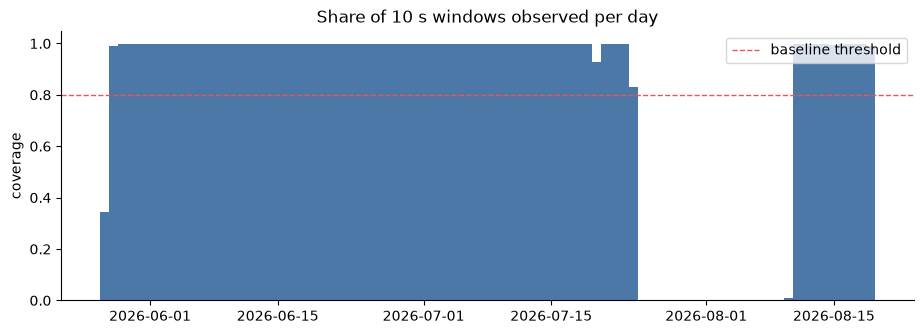

overall coverage 78.8%; 16 days without capture


local_date,coverage_ratio,longest_gap_min
date,f64,f64
2026-05-27,0.342593,945.983333
2026-07-24,0.830903,242.033333
2026-08-10,0.007986,1428.35


In [2]:
coverage = tables["agg_capture_coverage_daily"].sort("local_date")
fig, ax = plt.subplots()
ax.bar(coverage["local_date"], coverage["coverage_ratio"], color="#4c78a8", width=1.0)
ax.axhline(0.8, color="#e45756", lw=1, ls="--", label="baseline threshold")
ax.set_ylabel("coverage"); ax.set_title("Share of 10 s windows observed per day"); ax.legend()
plt.show()
print(f"overall coverage {coverage['observed_windows'].sum() / coverage['expected_windows'].sum():.1%}; "
      f"{coverage.filter(pl.col('coverage_ratio') == 0).height} days without capture")
coverage.filter((pl.col("coverage_ratio") > 0) & (pl.col("longest_gap_min") > 30)).select(
    "local_date", "coverage_ratio", "longest_gap_min")

## 2. Randomized vs stable devices

Modern phones rotate a random (locally administered) MAC per network or per scan, so raw MAC counts
overstate people. Stable addresses are the ones we can follow over time; randomized MACs are reported
separately and never mixed into per-device statistics.

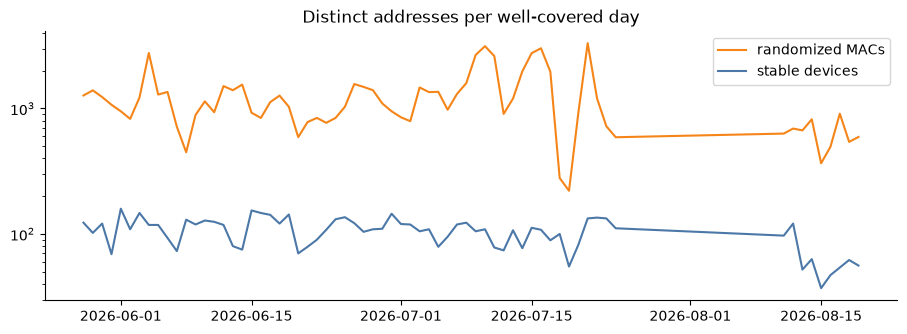

device_segment,devices,presence_ratio,median_session_duration,avg_rssi
str,u32,f64,f64,f64
"""randomized""",77509,0.03125,10.0,-64.0
"""passerby""",2158,0.029851,10.0,-74.0
"""regular""",498,0.093387,10.0,-74.0
"""resident""",10,0.900857,10.0,-72.141964
"""infrastructure""",9,0.869565,40.0,-74.718632


In [3]:
daily = tables["agg_network_daily"].filter(pl.col("coverage_ratio") >= 0.8).sort("local_date")
fig, ax = plt.subplots()
ax.plot(daily["local_date"], daily["randomized_macs"], label="randomized MACs", color="#f58518")
ax.plot(daily["local_date"], daily["stable_devices"], label="stable devices", color="#4c78a8")
ax.set_yscale("log"); ax.set_title("Distinct addresses per well-covered day"); ax.legend()
plt.show()

profile = tables["dim_device_profile"]
(profile.group_by("device_segment")
 .agg(pl.len().alias("devices"), pl.col("presence_ratio").median(), pl.col("median_session_duration").median(),
      pl.col("avg_rssi").median())
 .sort("devices", descending=True))

### Vendors

Manufacturer prefixes (OUI) survive hashing for stable addresses. The mix is telling: a large share
of stable devices passing the window are car head units and wearables rather than phones.

In [4]:
(tables["agg_vendor"].filter(pl.col("device_segment") != "randomized")
 .group_by("vendor").agg(pl.col("device_count").sum(), pl.col("devices_last_7d").sum())
 .sort("device_count", descending=True).head(12))

vendor,device_count,devices_last_7d
str,u32,u32
"""Aumovio""",413,21
"""Garmin""",222,14
"""Alpsalpine""",171,7
"""Murata Manufacturing""",156,9
"""SparkLAN""",127,14
…,…,…
"""Panasonic Automotive""",65,5
"""TomTom Software""",65,4
"""LG""",62,4


## 3. Rhythm: hour-of-week profile

Median distinct devices per covered hour, by local weekday and hour.

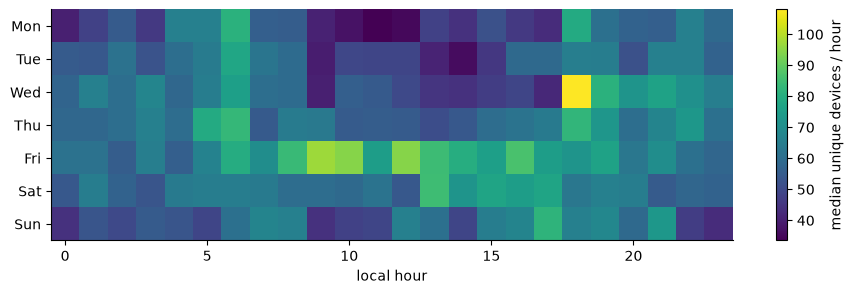

In [5]:
how = tables["agg_baseline_hour_of_week"].sort("local_weekday", "local_hour")
grid = np.full((7, 24), np.nan)
for row in how.iter_rows(named=True):
    grid[row["local_weekday"] - 1, row["local_hour"]] = row["unique_devices_p50"]
fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(grid, aspect="auto", cmap="viridis")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); ax.set_xlabel("local hour")
fig.colorbar(im, label="median unique devices / hour"); plt.show()

## 4. Clustering stable devices by daily rhythm

`feat_device_hour_profile` holds, for every stable device with enough observations, the share of its
activity in each weekday and weekend hour. K-means on these 48-dimensional profiles separates
day-time visitors, evening residents and always-on infrastructure without any labels.

silhouette by k: {2: 0.408, 3: 0.156, 4: 0.127, 5: 0.182, 6: 0.169} -> k = 2


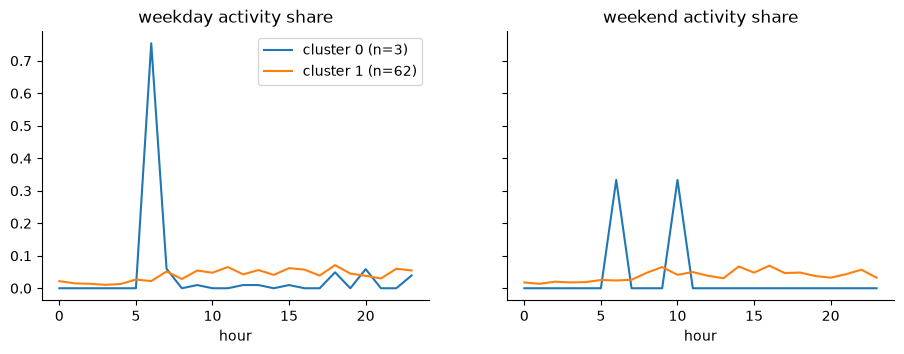

cluster,regular,infrastructure,passerby,resident
i32,u32,u32,u32,u32
0,3,null,null,null
1,38,9,5,10


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

hp = tables["feat_device_hour_profile"]
cols = [c for c in hp.columns if c.startswith(("wd_h", "we_h"))]
X = hp.select(cols).fill_null(0).to_numpy()

scores = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X)) for k in range(2, 7)}
best_k = max(scores, key=scores.get)
print("silhouette by k:", {k: round(v, 3) for k, v in scores.items()}, "-> k =", best_k)

model = KMeans(best_k, n_init=10, random_state=0).fit(X)
hp = hp.with_columns(pl.Series("cluster", model.labels_))
fig, axes = plt.subplots(1, 2, sharey=True)
for c in range(best_k):
    center = model.cluster_centers_[c]
    n = int((model.labels_ == c).sum())
    axes[0].plot(range(24), center[:24], label=f"cluster {c} (n={n})")
    axes[1].plot(range(24), center[24:])
axes[0].set_title("weekday activity share"); axes[1].set_title("weekend activity share")
axes[0].set_xlabel("hour"); axes[1].set_xlabel("hour"); axes[0].legend(); plt.show()

hp.group_by("cluster", "device_segment").len().pivot(on="device_segment", index="cluster", values="len").sort("cluster")

## 5. Anomalies

Each covered hour is compared with the median of the same hour-of-week over the previous four weeks.
Residuals on a log scale are standardised with a pooled MAD; |z| > 3.5 is flagged. The trailing
baseline means a holiday-driven level shift is absorbed after a few weeks instead of being flagged
forever.

43 of 1191 scored hours flagged (3.6%)


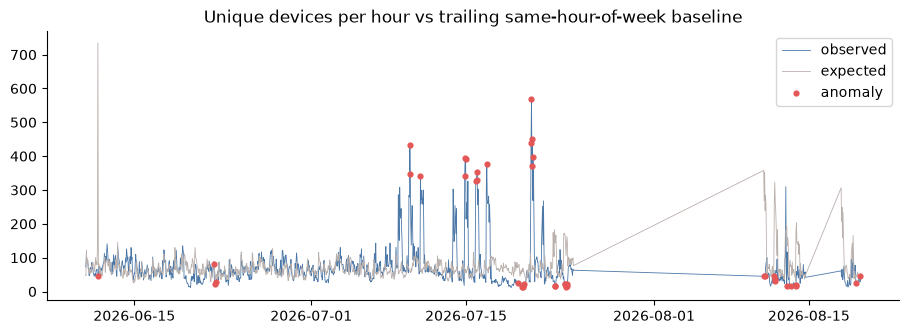

hour_start,local_weekday,local_hour,unique_devices,expected_unique_devices,z_unique_devices,packets_per_min,z_packets_per_min,driver
"datetime[μs, UTC]",i8,i8,u32,f64,f64,f64,f64,str
2026-07-20 22:00:00 UTC,2,0,568,57.5,4.70195,471.65,-0.150564,"""unique_devices"""
2026-08-11 22:00:00 UTC,3,0,32,323.5,-4.639703,539.5,-0.523583,"""unique_devices"""
2026-06-11 17:00:00 UTC,4,19,46,734.0,-4.399232,610.783333,-0.980218,"""unique_devices"""
2026-07-24 02:00:00 UTC,5,4,15,139.0,-4.193334,912.133705,0.5196,"""unique_devices"""
2026-07-24 01:00:00 UTC,5,3,13,105.0,-4.056292,927.716667,0.522813,"""unique_devices"""
2026-07-23 02:00:00 UTC,4,4,17,146.5,-4.050497,914.7,0.952054,"""unique_devices"""
2026-07-09 22:00:00 UTC,5,0,432,59.5,4.039464,863.247911,0.279669,"""unique_devices"""
2026-07-20 21:00:00 UTC,1,23,438,60.5,4.034042,213.008357,-1.974938,"""unique_devices"""
2026-07-23 01:00:00 UTC,4,3,16,144.0,-4.01503,1209.158774,1.16269,"""unique_devices"""


In [7]:
anom = tables["agg_anomaly_hourly"].sort("hour_start")
flagged = anom.filter(pl.col("is_anomaly"))
print(f"{flagged.height} of {anom.height} scored hours flagged ({flagged.height / max(anom.height, 1):.1%})")

fig, ax = plt.subplots()
ax.plot(anom["hour_start"], anom["unique_devices"], lw=0.6, color="#4c78a8", label="observed")
ax.plot(anom["hour_start"], anom["expected_unique_devices"], lw=0.6, color="#bab0ac", label="expected")
ax.scatter(flagged["hour_start"], flagged["unique_devices"], color="#e45756", s=12, zorder=3, label="anomaly")
ax.set_title("Unique devices per hour vs trailing same-hour-of-week baseline"); ax.legend(); plt.show()

flagged.select("hour_start", "local_weekday", "local_hour", "unique_devices", "expected_unique_devices",
               "z_unique_devices", "packets_per_min", "z_packets_per_min", "driver").sort(
    pl.col("z_unique_devices").abs(), descending=True).head(10)

## 6. How predictable is next week?

Hold out the last 20 % of well-covered hours (chronologically) and forecast hourly unique devices with:

1. **seasonal naive**: same hour one week earlier (`lag_168h`);
2. **ridge regression** on lag, rolling and cyclical features.

`baseline_unique_devices` in `feat_network_hourly` is computed over the full history, so it would leak
the test period into training and is deliberately left out.

train 1015 h, test 254 h
 seasonal naive: MAE 64.5 devices/hour (89% of mean)
          ridge: MAE 52.8 devices/hour (73% of mean)


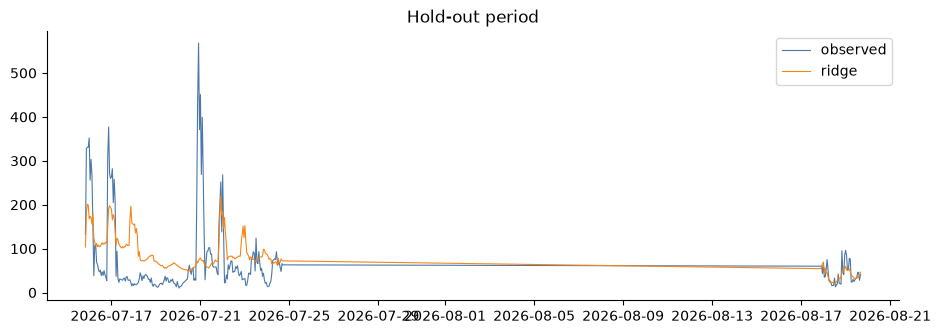

In [8]:
from sklearn.linear_model import RidgeCV

features = ["unique_devices_lag_24h", "unique_devices_lag_168h", "unique_devices_mean_7d",
            "unique_devices_std_7d", "packets_per_min_lag_24h", "hour_sin", "hour_cos",
            "weekday_sin", "weekday_cos"]
fh = (tables["feat_network_hourly"].filter(pl.col("coverage_ratio") >= 0.8)
      .drop_nulls(features + ["unique_devices"]).sort("hour_start"))
split = int(fh.height * 0.8)
train, test = fh.head(split), fh.tail(fh.height - split)

def arr(frame, cols): return frame.select(cols).cast(pl.Float64).to_numpy()
y_test = arr(test, "unique_devices").ravel()
ridge = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(arr(train, features), arr(train, "unique_devices").ravel())
preds = {"seasonal naive": arr(test, "unique_devices_lag_168h").ravel(),
         "ridge": ridge.predict(arr(test, features))}

def mae(p): return float(np.mean(np.abs(p - y_test)))
print(f"train {train.height} h, test {test.height} h")
for name, p in preds.items():
    print(f"{name:>15}: MAE {mae(p):.1f} devices/hour ({mae(p) / y_test.mean():.0%} of mean)")

fig, ax = plt.subplots()
ax.plot(test["hour_start"], y_test, color="#4c78a8", lw=0.8, label="observed")
ax.plot(test["hour_start"], preds["ridge"], color="#f58518", lw=0.8, label="ridge")
ax.set_title("Hold-out period"); ax.legend(); plt.show()

**Reading the result.** Hour-to-hour traffic is noisy (passing cars and phones dominate the
counts), so point forecasts carry a large error. Any level shift, such as a holiday period, also
lands straight in the hold-out window. Ridge beats the seasonal-naive benchmark mostly through the
7-day rolling mean, which adapts to such shifts. This is why the dashboard shows a *band*
(p10-p90 of the same hour-of-week) and flags only hours far outside it, rather than promising a
single predicted number.